# Asset Allocation When Expected Returns Are Unreliable #

#### Yuxin Jin, Liang Ma, Bingchu Zhao

### Table of Contents

1. [Introduction](#1-introduction)
1. [Mathematical Model](#2-mathematical-model)
1. [Implementation and Solution](#3-implementation)
1. [Discussion of Results](#4-results-discussion)
1. [Conclusion](#5-conclusion)


## 1. Introduction ##
Our project studies whether robust optimization can make asset allocation more reliable when expected returns estimated from historical data are uncertain. We build and test the model using 30 U.S. industry portfolios and compare it with nominal and equally weighted portfolios. Asset allocation is the process of deciding how to divide money among different assets. One common approach is to estimate the average return of each asset from historical data and invest more in assets with higher estimated returns. However, historical mean returns are not always reliable. If an industry has a high estimated return mainly because of sampling error, a normal optimization model may still invest most or even all of the money in that industry. In this case, the model is optimizing noise instead of finding a portfolio that is likely to perform well in the future. This problem is important because even a small estimation error can lead to a completely different and highly concentrated portfolio.

Portfolio optimization has been widely studied since Markowitz introduced a mathematical approach to portfolio selection in 1952 ([Markowitz, 1952](https://onlinelibrary.wiley.com/doi/10.1111/j.1540-6261.1952.tb01525.x)). His work showed that investment decisions should consider the performance of the entire portfolio instead of evaluating each asset separately. However, any optimization model still needs estimates of future returns, and the final portfolio can be very sensitive to errors in those estimates.

To address this problem, our project uses the robust optimization approach developed by Bertsimas and Sim ([Bertsimas and Sim, 2004](https://doi.org/10.1287/opre.1030.0065)). We introduce an adversary that can reduce the estimated returns of up to $\Gamma$ industries. A larger $\Gamma$ means that the model is less confident in the historical estimates and becomes more conservative. By using linear programming duality, we can rewrite this investor-versus-adversary problem as a single linear program that can be solved efficiently.

Our data comes from the Kenneth R. French Data Library ([30 Industry Portfolios](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/data_library/det_30_ind_port.html)). We use value-weighted daily returns for 30 U.S. industry portfolios. For the main experiment, the 2015–2020 data is used for training, 2021–2022 is used to select $\Gamma$, and 2023–2025 is kept as an out-of-sample test. We also repeat the same procedure across the longer historical record to examine the model under different market conditions.

To simplify the problem, we assume that all money must be invested, while borrowing and short selling are not allowed. We also ignore transaction costs and taxes and treat the portfolios as being rebalanced daily. The uncertainty of each industry is measured as twice the standard error of its historical mean return. The rest of the report introduces the mathematical model, explains its implementation in Julia and JuMP, discusses the results and limitations, and summarizes our main findings and possible future directions.


## 2. Mathematical Model ##

### 2.1 Original Problem

The original model is one that considers only the maximization of returns through capital allocation. We regard the original problem as a linear program.

The key rules are:

1. We need to use up all the principal and cannot take out any loans.
2. Purchases only; short selling is prohibited.
3. We aim to maximize returns.

$\textbf{Sets}$

Let $E$ = \{1,…,30\} be the set of all available assets from the dataset.

$\textbf{Data}$

Let $\mu_i$ be a constant representing the estimated mean return for asset $i \in E$.

$\textbf{Decision variables}$

Let $x_i$ be a variable representing the portfolio weight (proportion) of the total principal invested in asset $i \in E$.

$\textbf{Constraints}$

1. Budget constraint:

$\quad \quad$ The entire principal must be invested without taking any loans: 

$$\sum_{i \in E} x_i = 1$$

2. No short-selling constraint:

$\quad \quad$ Only purchasing is allowed and short selling is prohibited. This means that portfolio weights cannot be negative.  

$$x_i \geq 0 \quad \forall i \in E$$

$\textbf{Objective function}$

The objective is to maximize the returns:

$$\max_{x} \quad \sum_{i \in E} \mu_i x_i$$

### 2.2 The Adversary

While the model seems effective, it ends up optimizing estimation noise rather than expected return. The reason is that an optimization model that relies directly on these estimates may place excessive emphasis on assets whose estimated returns are high simply because of sampling error.

Therefore, a hypothetical adversary is introduced. The adversary is allowed to reduce the estimated mean returns of up to $\Gamma$ assets to minimize our portfolio's return. In this problem, portfolio weights $x_i$ are treated as fixed parameters.

$\textbf{Sets}$

Let $E$ = \{1,…,30\} be the set of all available assets from the dataset.

$\textbf{Data}$

$d_i = 2 \times \text{SE}_i$, which represents the maximum possible reduction (penalty) in the mean return for asset $i \in E$. It is twice the standard error of the historical mean return of asset $i \in E$.

Let $\Gamma$ be the uncertainty amount, an integer from 0 to 30, which represents the maximum number of assets to be penalized.

Let $\mu_i$ be a constant representing the estimated mean return for asset $i \in E$.

Let $x_i$ be the portfolio weight for asset $i \in E$, treated as a given parameter since these weights are fixed by us (the investor).

$\textbf{Decision variables}$

Let $r_i$ be a variable representing the proportion of the maximum penalty $d_i$ that the adversary chooses to apply to asset $i \in E$.

$\textbf{Constraints}$

1. Uncertainty amount constraint: 

$\quad \quad$ At most $\Gamma$ assets can be penalized by the adversary: 

$$\sum_{i \in E} r_i \leq \Gamma$$

2. Penalty proportion bound constraint:

$\quad \quad$ The penalty for any type of asset cannot exceed 100% of the maximum possible reduction $d_i$. Apart from that, the penalty cannot be negative: 

$$0 \leq r_i \leq 1 \quad \forall i \in E$$

$\textbf{Objective function}$

The objective for the adversary is to minimize our returns:

$$\min_{r} \quad \sum_{i \in E} (\mu_i - r_i d_i) x_i$$

### 2.3 The New Model

The adversary's objective is minimizing our returns, which is equivalent to maximizing the penalty deducted from our expected returns. Therefore, the adversary's objective can be rewritten as the following expression:

$$\sum_{i \in E} \mu_i x_i - \max_{r} \sum_{i \in E} r_i d_i x_i$$

Therefore, we need to optimize $x_i$ to maximize our returns under above situation:

$$\max_{x \ge 0,\ \sum_{i \in E} x_i = 1} ( \sum_{i \in E} \mu_i x_i - \max_{r} \sum_{i \in E} r_i d_i x_i )$$

To simplify the model, we need to find the dual of the adversary's maximization problem, which will become a minimization problem.

From 2.2, the adversary's maximization problem is:

$$\begin{aligned}
\max_{r} \quad & \sum_{i \in E} r_i d_i x_i \\
\text{s.t. } \quad
& \sum_{i \in E} r_i \leq \Gamma\\
& r_i \leq 1 \quad \forall i \in E\\
& r_i \geq 0 \quad \forall i \in E
\end{aligned}
$$

Let $z \geq 0$ be the dual variable associated with the uncertainty amount constraint $\sum_{i \in E} r_i \leq \Gamma$.

Let $p_i \geq 0$ be the dual variables associated with the penalty proportion upper bound constraints $r_i \leq 1$.

The dual is
$$\begin{aligned}
\min_{z, p} \quad & \Gamma z + \sum_{i \in E} p_i \\
\text{s.t. } \quad
& z + p_i \ge d_i x_i \quad \forall i \in E\\
& z \ge 0 \\
& p_i \ge 0 \quad \forall i \in E
\end{aligned}
$$

The adversary's LP is feasible ($r = 0$) and its feasible region is bounded ($0 \leq r_i \leq 1$), so by the Strong Duality Theorem, $$\max_{r} \sum_{i \in E} r_i d_i x_i  = \min_{z, p} (\Gamma z + \sum_{i \in E} p_i)$$

Therefore, $$\max_{x \ge 0,\ \sum_{i \in E} x_i = 1} ( \sum_{i \in E} \mu_i x_i - \max_{r} \sum_{i \in E} r_i d_i x_i ) = \max_{x \ge 0,\ \sum_{i \in E} x_i = 1} \left[ \sum_{i \in E} \mu_i x_i - \min_{z, p} \left( \Gamma z + \sum_{i \in E} p_i \right) \right]$$

Since the outer problem maximizes, any dual-feasible $(z, p)$ certifies a lower bound on the worst case, so the inner minimization can be dropped and $(z, p)$ chosen jointly with $x$. This gives a single maximization problem:

$$\begin{aligned}
\max_{x, z, p} \quad & \sum_{i \in E} \mu_i x_i - \Gamma z - \sum_{i \in E} p_i\\
\text{s.t. } \quad
& z + p_i \ge d_i x_i \quad \forall i \in E\\
& \sum_{i \in E} x_i = 1 \\
& x_i, z, p_i \ge 0 \quad \forall i \in E
\end{aligned}
$$

#### The new model

$\textbf{Sets}$

Let $E$ = \{1,…,30\} be the set of all available assets from the dataset.

$\textbf{Data}$

$d_i = 2 \times \text{SE}_i$, which represents the maximum possible reduction (penalty) in the mean return for asset $i \in E$. It is twice the standard error of the historical mean return of asset $i \in E$.

Let $\Gamma$ be the uncertainty amount, an integer from 0 to 30, which represents the maximum number of assets to be penalized.

Let $\mu_i$ be a constant representing the estimated mean return for asset $i \in E$.

$\textbf{Decision variables}$

Let $x_i$ be a variable representing the portfolio weight (proportion) of the total principal invested in asset $i \in E$.

Let the dual variable $z$ represent the marginal cost of the adversary's uncertainty amount $\Gamma$.

Let the dual variable $p_i$ represent the marginal cost of the adversary's penalty bound on asset $i \in E$.

$\textbf{Constraints}$

1. The adversary's penalty constraint:

$\quad \quad$ The gain of the adversary which may be extracted from $d_i x_i$ must be covered by the sum of the marginal cost of the adversary's uncertainty amount ($z$) and the marginal cost of the adversary's penalty bound on asset $i \in E$ ($p_i$).

$$z + p_i \ge d_i x_i \quad \forall i \in E$$

2. Budget constraint:

$\quad \quad$ The entire principal must be invested without taking any loans: 

$$\sum_{i \in E} x_i = 1$$

3. No short-selling constraint:

$\quad \quad$ Only purchasing is allowed and short selling is prohibited. This means that portfolio weights cannot be negative.  

$$x_i \geq 0 \quad \forall i \in E$$

4. Nonnegativity:

$$p_i \geq 0 \quad \forall i \in E$$

$$z \geq 0$$

$\textbf{Objective function}$

The objective is to maximize the return under the worst case (the attack of the adversary), which by the derivation in 2.3 is the estimated return minus the adversary's priced-out damage:

$$\max_{x,\, z,\, p} \quad \sum_{i \in E} \mu_i x_i - \Gamma z - \sum_{i \in E} p_i$$

## 3. Implementation ##

We implement the model in Julia with JuMP and the HiGHS solver. The data file is a fixed snapshot of the Ken French "30 Industry Portfolios (Daily)" CSV, generated from the May 2026 CRSP database. The file ships several tables; we parse the first one, convert percent to decimal, and verify the sample size and the absence of the library's missing-value code.


In [1]:
using JuMP, HiGHS, Statistics, Plots
gr()

# read the value-weighted daily table out of the Ken French CSV. the file stacks four
# tables on the same 30 industry columns (value-weighted returns, then equal-weighted,
# then two of firm counts), and the only thing marking a data row is that it starts with
# an 8-digit date. so find the first such row, take the line above it as the header, and
# stop at the first line that is not a data row, which is where the next table begins.
function load_vw_daily(path)
    lines = readlines(path)
    i0 = findfirst(l -> occursin(r"^\s*\d{8},", l), lines)       # first data row of the first table
    industries = String.(strip.(split(lines[i0-1], ','))[2:end]) # header row holds industry names
    dates = Int[]
    rows = Vector{Vector{Float64}}()
    for l in lines[i0:end]
        m = match(r"^\s*(\d{8}),(.*)$", l)   # the date and the 30 numbers, captured separately
        m === nothing && break               # first non-data line: the next table starts here
        push!(dates, parse(Int, m.captures[1]))
        push!(rows, parse.(Float64, split(m.captures[2], ',')))
    end
    # the file quotes percent (0.51 means +0.51% on the day), every formula below wants
    # decimals, so convert once here instead of in each caller
    R = reduce(vcat, transpose.(rows)) ./ 100
    return dates, industries, R
end

# the CSV snapshot sits in the same folder as this notebook. it is a frozen copy of the
# May 2026 build, since the library revises recent history every month.
dates, industries, R = load_vw_daily("30_Industry_Portfolios_Daily.csv")

# R now runs from 1926 to 2026; this mask picks the 2015-2025 rows we use. the three
# checks fail loudly rather than letting a parsing mistake reach the model.
sel_all = (dates .>= 20150101) .& (dates .<= 20251231)
@assert length(industries) == 30      # 30 columns means we read an industry table, not a count table
@assert sum(sel_all) == 2766          # the trading-day count we checked separately when choosing the data
@assert all(R[sel_all, :] .> -0.98)   # French codes a missing observation as -99.99, which is -0.9999
                                      # after the divide. no industry index drops 98% in one day, so
                                      # this catches missing codes without catching real returns.
println("data checks passed")


data checks passed


Two model inputs: the mean daily return $\hat\mu_i$ and the uncertainty scale $d_i = 2\,\widehat{\mathrm{SE}}(\hat\mu_i)$. Because the standard error is proportional to each industry's volatility, $d_i$ is effectively a volatility penalty, which will matter when we interpret which industries survive at high $\Gamma$.

Annualized numbers below are daily figures scaled by 252 trading days.


annualized mean returns: min 2.2

%, max 18.5%
annualized 2xSE:         min 11.2%, max 38.8%
average pairwise correlation: 0.63

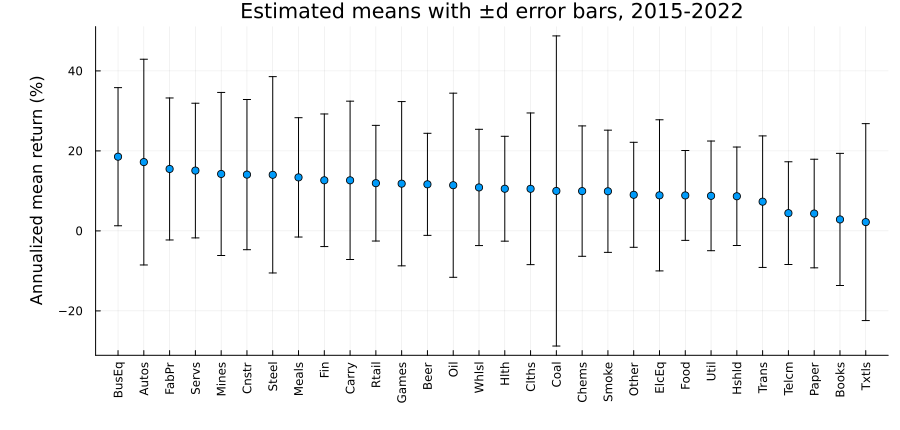

In [2]:
# ---- the two inputs the model needs, both from the estimation window only
sel_est = (dates .>= 20150101) .& (dates .<= 20221231)   # 2023-2025 is in R but is not read here
Rest = R[sel_est, :]
T = size(Rest, 1)                            # trading days in the estimation window

μ = vec(mean(Rest, dims=1))                  # sample mean daily return, what a nominal optimizer would trust

# d_i is how far that mean could plausibly be off. the standard error of a mean is
# std/sqrt(T), and we take twice it, roughly a 95% half-width. it is the amount the
# adversary may subtract from any one industry, so it sets how strong the adversary is.
d = 2 .* vec(std(Rest, dims=1)) ./ sqrt(T)

ann(r) = 100 * 252 * r                       # daily decimal -> annualized percent, for printing only

println("annualized mean returns: min ", round(minimum(ann.(μ)), digits=1),
        "%, max ", round(maximum(ann.(μ)), digits=1), "%")
println("annualized 2xSE:         min ", round(minimum(ann.(d)), digits=1),
        "%, max ", round(maximum(ann.(d)), digits=1), "%")

# the model's probabilistic guarantee assumes the 30 estimation errors are independent,
# and industries move together, so measure it here. subtracting 30 drops the diagonal of
# ones and 30*29 counts the remaining ordered pairs.
C = cor(Rest)
println("average pairwise correlation: ", round((sum(C) - 30) / (30 * 29), digits=2))

# the premise in one picture: thirty estimated means and their ±d bands on one axis,
# sorted by mean so the overlap is visible at a glance
ord = sortperm(μ, rev=true)
p_in = scatter(1:30, ann.(μ[ord]), yerror = ann.(d[ord]), legend = false,
               xticks = (1:30, industries[ord]), xrotation = 90, size = (900, 430),
               bottom_margin = 10Plots.mm, left_margin = 10Plots.mm,
               ylabel = "Annualized mean return (%)",
               title = "Estimated means with ±d error bars, 2015-2022")
savefig(p_in, "fig_inputs.png")
p_in


The robust model is the dual reformulation derived in Section 2, written as one JuMP function so every later experiment reuses the same code.

In [3]:
# ---- the robust model as a single LP
# the two-level game (we choose x, then an adversary lowers the estimated mean of up to Γ
# industries by d_i each) cannot go to a solver directly, but the adversary's inner problem
# is itself an LP, so replacing it by its dual collapses the game into the one LP below.
# derivation in Section 2. returns the weights, the guaranteed worst-case value, and z.
function solve_robust(μ, d, Γ)
    n = length(μ)
    m = Model(HiGHS.Optimizer)
    set_silent(m)                   # the solver's own log is not part of the report

    @variable(m, x[1:n] >= 0)       # portfolio weights. nonnegative means no short selling
    @variable(m, z >= 0)            # dual of the adversary's budget constraint sum(r_i) <= Γ
    @variable(m, p[1:n] >= 0)       # duals of the adversary's per-asset caps r_i <= 1

    # all capital is invested: the weights are shares of one dollar and must exhaust it
    @constraint(m, sum(x) == 1)

    # dual feasibility, one row per industry. whatever the adversary could take from
    # industry i, d_i * x_i, has to be covered by the budget price z plus the per-asset
    # price p_i, so this is what makes z and p pay for the damage.
    @constraint(m, dualfeas[i in 1:n], z + p[i] >= d[i] * x[i])

    # estimated return minus what the adversary can remove, priced through the duals.
    # maximizing this is exactly maximizing the worst case.
    @objective(m, Max, sum(μ[i] * x[i] for i in 1:n) - Γ * z - sum(p))

    optimize!(m)
    return value.(x), objective_value(m), value(z)
end;   # the semicolon keeps IJulia from echoing the function object under the cell


Following Prof. Smith's suggestion, we validate the model on a five-asset toy problem before touching the full dataset. The toy is small enough that the dual reformulation can be checked against methods that use no duality at all, and we run two such checks for every $\Gamma$ from 0 to 5. First, once the LP has picked a portfolio, the adversary's true worst case follows from a sort: hit the $\Gamma$ assets with the largest $d_i x_i$. Second, we re-solve the whole two-level problem by brute force, adding one epigraph constraint for every attack subset of size $\Gamma$. All three numbers must agree to solver precision.

In [4]:
# ---- validating the reformulation
# the dualization above is the one step where a silent algebra slip gives a model that
# still runs and is wrong everywhere. following the instructor's suggestion on the
# proposal, we check it on a five-industry toy against two methods that use no duality at
# all. all three have to agree.

# check 1: for fixed weights the adversary just hits the Γ largest d_i * x_i,
# so the worst case can be computed by sorting
worst_direct(x, μ, d, Γ) = sum(μ .* x) - sum(sort(d .* x, rev=true)[1:Γ])

# all ways to choose k industries out of 1:n, built recursively: pick the largest member
# `last`, then choose the other k-1 below it. affordable only because the toy has 5 assets.
function subsets_of_size(n, k)
    k == 0 && return [Int[]]
    result = Vector{Vector{Int}}()
    for last in k:n
        for head in subsets_of_size(last - 1, k - 1)
            push!(result, vcat(head, last))
        end
    end
    return result
end

# check 2: re-solve the whole two-level problem without duality. t stands for the value
# after the worst attack, and one constraint per attack subset holds t below the value
# under that subset, so maximizing t optimizes against every attack at once.
function solve_enum(μ, d, Γ)
    n = length(μ)
    m = Model(HiGHS.Optimizer)
    set_silent(m)
    @variable(m, x[1:n] >= 0)                        # portfolio weights, no short selling
    @variable(m, t)                                  # the worst case over all attacks, free in sign
    @constraint(m, sum(x) == 1)                      # all capital invested
    for S in subsets_of_size(n, Γ)                   # one row per attack subset S of size Γ:
        @constraint(m, t <= sum(μ[i] * x[i] for i in 1:n) - sum(d[i] * x[i] for i in S; init = 0.0))
    end                                              # t is no larger than the value under S
    @objective(m, Max, t)
    optimize!(m)
    return value.(x), objective_value(m)
end

# run all three on the first five industries, at every budget a five-asset problem allows
ntoy = 5
μ_toy, d_toy = μ[1:ntoy], d[1:ntoy]
println("toy industries: ", join(industries[1:ntoy], ", "))
for Γ in 0:ntoy
    x1, o1, _ = solve_robust(μ_toy, d_toy, Γ)        # our dual reformulation
    x2, o2 = solve_enum(μ_toy, d_toy, Γ)             # brute force, no duality
    w1 = worst_direct(x1, μ_toy, d_toy, Γ)           # direct sort, no optimization
    diff = max(abs(o1 - o2), abs(o1 - w1))
    println("Γ = ", Γ, ": dual LP = ", round(o1, sigdigits=6),
            ", enumeration LP = ", round(o2, sigdigits=6),
            ", direct sort = ", round(w1, sigdigits=6),
            ", max diff = ", round(diff, sigdigits=3))
    @assert diff < 1e-9   # the three share no code path, so this fails loudly if the model breaks
end
println("toy validation passed")


toy industries: Food, Beer, Smoke, Games, Books
Γ = 

0: dual LP = 0.000468322, enumeration LP = 0.000468322, direct sort = 0.000468322, max diff = 0.0
Γ = 1: dual LP = 0.000271304, enumeration LP = 0.000271304, direct sort = 0.000271304, max diff = 5.42e-20
Γ = 2: dual LP = 0.000130351, enumeration LP = 0.000130351, direct sort = 0.000130351, max diff = 1.63e-19
Γ = 3: dual LP = 1.13456e-5, enumeration LP = 1.13456e-5, direct sort = 1.13456e-5, max diff = 1.63e-19
Γ = 4: dual LP = -4.42192e-5, enumeration LP = -4.42192e-5, direct sort = -4.42192e-5, max diff = 0.0
Γ = 5: dual LP = -4.42192e-5, enumeration LP = -4.42192e-5, direct sort = -4.42192e-5, max diff = 0.0
toy validation passed


With the model validated we solve the full 30-industry problem. The runs below show how the optimal portfolio changes as the adversary's budget grows.


In [5]:
# ---- the full problem at four budget levels
# Γ = 0 trusts the estimates completely, Γ = 30 assumes every one of them could be wrong,
# and 5 and 15 sit in between. the largest holdings show how the portfolio changes as the
# model is asked to trust the data less.
println("full model on all 30 industries:")
for Γ in (0, 5, 15, 30)
    x, obj, z = solve_robust(μ, d, Γ)
    # a weight the solver reports as 1e-12 is vertex dust, not a position, so an industry
    # counts as held only above 1e-4
    holdings = [(industries[i], 100 * x[i]) for i in 1:30 if x[i] > 1e-4]
    sort!(holdings, by = h -> -h[2])   # largest positions first, so the top five really is the top five
    top5 = join([h[1] * " " * string(round(h[2], digits=1)) * "%" for h in holdings[1:min(5, end)]], ", ")
    println("Γ = ", Γ, ": worst-case return ", round(ann(obj), digits=2), "%, ",
            length(holdings), " holdings; largest: ", top5)
end


full model on all 30 industries:
Γ = 0

: worst-case return 18.55%, 1 holdings; largest: BusEq 100.0%
Γ = 5: worst-case return 8.39%, 25 holdings; largest: Food 6.0%, Hshld 5.4%, Beer 5.2%, Hlth 5.1%, Other 5.1%
Γ = 15: worst-case return 2.17%, 30 holdings; largest: Food 4.9%, Hshld 4.5%, Beer 4.3%, Telcm 4.3%, Hlth 4.2%
Γ = 30: worst-case return 1.28%, 1 holdings; largest: BusEq 100.0%


Finally we sweep $\Gamma$ over its whole range 0-30. This produces the price-of-robustness curve (how much worst-case guaranteed return each unit of protection costs) and lets us verify the theoretical prediction that the curve's slope equals $-z^*$, the negative of the budget constraint's dual variable.

The check compares finite differences of the curve against $-z^*$; between breakpoints of the piecewise-linear curve the two agree exactly.


In [6]:
# ---- the whole robustness path at once
# solve at every integer budget from 0 to 30 and keep three series: the guaranteed
# worst-case value (the price-of-robustness curve), the dual z, and how many industries
# are held. each solve is a 61-variable LP and takes milliseconds.
Γ_range = 0:30
worst_case = Float64[]
z_values = Float64[]
num_holdings = Int[]
for Γ in Γ_range
    x, obj, z = solve_robust(μ, d, Γ)
    push!(worst_case, obj)
    push!(z_values, z)
    push!(num_holdings, count(x .> 1e-4))   # same dust threshold as above
end

# z is the dual on the adversary's budget constraint, so it is that budget's shadow price:
# one more unit of Γ should cost us exactly z, and the curve's slope must equal -z*. a
# finite difference of the curve checks the theory against the solver's own output, and
# the two agree wherever the curve is straight between the two Γ being differenced.
println("slope of the curve vs -z* (equal on linear stretches):")
for k in 1:10
    println("Γ = ", Γ_range[k], ": slope = ", round(worst_case[k+1] - worst_case[k], sigdigits=4),
            ", -z* = ", round(-z_values[k], sigdigits=4))
end


slope of the curve vs -z* (equal on linear stretches):
Γ = 0: slope = -0.0002265, -z* = -0.0006851
Γ = 1: slope = -6.624e-5, -z* = -9.391e-5
Γ = 2: slope = -4.511e-5, -z* = -5.133e-5
Γ = 3: slope = -3.586e-5, -z* = -4.087e-5
Γ = 4: slope = -2.945e-5, -z* = -3.532e-5
Γ = 5: slope = -2.653e-5, -z* = -2.653e-5
Γ = 6: slope = -2.614e-5, -z* = -2.653e-5
Γ = 7: slope = -2.549e-5, -z* = -2.549e-5
Γ = 8: slope = -2.549e-5, -z* = -2.549e-5
Γ = 9: slope = -2.549e-5, -z* = -2.549e-5


First the certified worst case at every budget, the price-of-robustness curve itself.


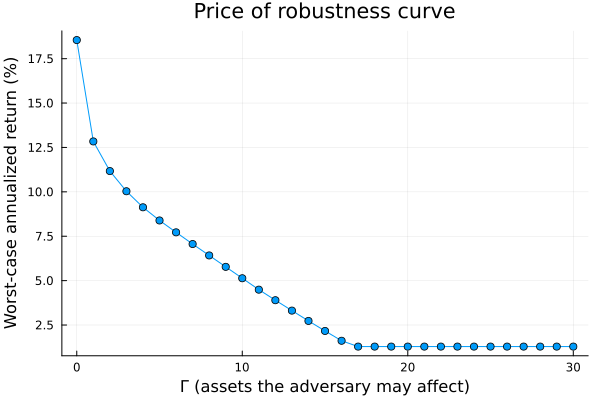

In [7]:
# the price of robustness: how much guaranteed return is given up for each extra industry
# the adversary may attack. annualized here for reading; the model works in daily decimals.
p_price = plot(Γ_range, ann.(worst_case), marker = :circle, legend = false,
     xlabel = "Γ (assets the adversary may affect)",
     ylabel = "Worst-case annualized return (%)",
     title = "Price of robustness curve")
savefig(p_price, "fig_price_curve.png")   # saved under the name section 4 links, so the report rebuilds from the notebook alone
p_price


Then the same sweep read as portfolio shape: how many industries are held at each level of distrust.


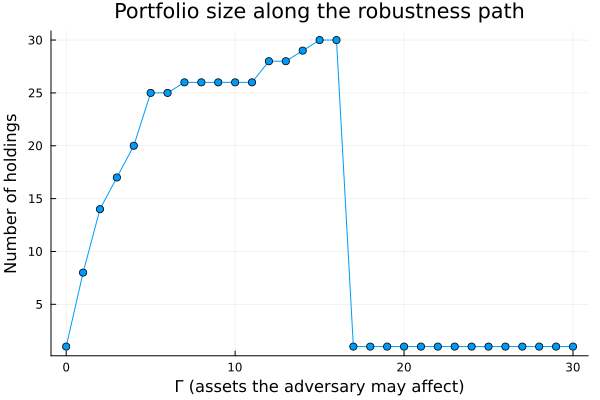

In [8]:
# how many industries the optimal portfolio holds along the same path. plotted separately
# from the curve above because the two answer different questions: what robustness costs,
# and what it does to the shape of the portfolio.
p_hold = plot(Γ_range, num_holdings, marker = :circle, legend = false,
     xlabel = "Γ (assets the adversary may affect)",
     ylabel = "Number of holdings",
     title = "Portfolio size along the robustness path")
savefig(p_hold, "fig_holdings.png")
p_hold


Everything above is in-sample: the inputs were fitted on 2015-2022 and every portfolio was judged against the same window. The next few cells choose $\Gamma$ without looking at the period the portfolio is then scored on, and then score it once.

The data splits into three blocks of calendar time. 2015-2020 fits $\hat\mu_i$ and $d_i$, 2021-2022 scores the 31 portfolios that come out of a $\Gamma$ sweep on that fit, and 2023-2025 is read only after every weight is frozen. The criterion is the Sharpe ratio, a portfolio's mean return divided by its volatility with a risk-free rate of exactly zero. We score on it because raising $\Gamma$ buys stability with return, and the ratio is what prices that trade. So $\Gamma^*$ is the level of distrust that paid off best on data the model was not fitted on. It is the smallest $\Gamma$ whose validation Sharpe comes within `1e-4` of the best, a tolerance that keeps two numerically equal scores from being separated by a last bit.


In [9]:
using Printf

# three disjoint calendar blocks. the upper bound on the holdout matters, since the CSV
# runs past 2025-12-31 and an open-ended mask would pull those rows in.
win(dv, lo, hi) = (dv .>= lo) .& (dv .<= hi)
sel_tr = win(dates, 20150101, 20201231)
sel_va = win(dates, 20210101, 20221231)
sel_ho = win(dates, 20230101, 20251231)
@assert !any(sel_est .& sel_ho)         # no day is used both to fit and to score
@assert (sel_tr .| sel_va) == sel_est   # train and validation partition the estimation window

# section 2's estimator, plus the scoring convention: a weight vector is read as a
# daily-rebalanced constant-weight book, so the day's return is x'R_t.
fit_inputs(Rw) = (vec(mean(Rw, dims=1)), 2 .* vec(std(Rw, dims=1)) ./ sqrt(size(Rw, 1)))
clean(x) = (y = max.(x, 0.0); y ./ sum(y))   # clamp the LP's -0.0 entries, renormalize
sharpe(r) = sqrt(252) * mean(r) / std(r)
held_thresh = 1e-4    # a real holding, against solver dust around 1e-16
tie_tol = 1e-4        # two validation Sharpes closer than this count as tied

# the whole selection as a function of a data block, so the leakage audit further down can
# rerun it on truncated data instead of reimplementing it.
function select_and_fit(dv, Rw)
    mu_f, d_f = fit_inputs(Rw[win(dv, 20150101, 20201231), :])          # fit on the train block
    X = [clean(solve_robust(mu_f, d_f, G)[1]) for G in 0:30]            # one candidate book per Γ
    s = [sharpe(Rw[win(dv, 20210101, 20221231), :] * x) for x in X]     # each scored on validation
    ties = [G for G in 0:30 if abs(s[G+1] - maximum(s)) < tie_tol]      # maximizers, within tolerance
    x_star = clean(solve_robust(fit_inputs(Rw[win(dv, 20150101, 20221231), :])...,
                                minimum(ties))[1])                      # refit on the full window
    return ties, X, s, x_star
end

tied, X_tr, sh_va, x_rob = select_and_fit(dates, R)
Gamma_star = minimum(tied)

# four budgets that carry the shape of the sweep: the trust-everything end, the dip just
# past it, the best score, and the point where the fit falls back to a single industry.
println("validation Sharpe by budget, fitted on 2015-2020 and scored on 2021-2022")
for G in (0, 1, 11, 13)
    @printf("  Γ = %2d: %2d holdings, Sharpe %7.4f\n", G, count(X_tr[G+1] .> held_thresh), sh_va[G+1])
end
@printf("selected Γ* = %d\n", Gamma_star)


validation Sharpe by budget, fitted on 2015-2020 and scored on 2021-2022


  Γ =  0:  1 holdings, Sharpe -0.2279
  Γ =  1:  4 holdings, Sharpe -0.2741


  Γ = 11: 26 holdings, Sharpe  0.2204
  Γ = 13:  1 holdings, Sharpe  0.1618
selected Γ* = 11


With $\Gamma^*$ chosen, the inputs are refit on the full 2015-2022 window and three books are frozen. The next cell scores all three on the holdout, which is read here for the first time.

- The robust book at $\Gamma^*$, which is the model's own answer at the level of distrust the validation years selected.
- The nominal book at $\Gamma = 0$, the same LP with the adversary given no budget. It trusts the estimates completely and puts everything in the single highest-mean industry, so it shows what the robust book is buying protection against.
- The equal-weight book, which gives each of the 30 industries $1/30$ of the capital and ignores the estimates entirely. A rule that cannot beat it has not earned the machinery it costs.


In [10]:
# with no adversary budget the Γ = 0 objective is the unperturbed in-sample mean of the
# single best industry, so that number bounds nothing. only the Γ* row is a real bound.
x_nom = clean(solve_robust(μ, d, 0)[1])
x_ew = fill(1 / 30, 30)
books = [("robust Γ=$Gamma_star", x_rob), ("nominal Γ=0", x_nom), ("equal weight 1/N", x_ew)]
@printf("LP worst-case bound %.2f%% at Γ* = %d, against %.2f%% at Γ = 0\n",
        ann(solve_robust(μ, d, Gamma_star)[2]), Gamma_star, ann(solve_robust(μ, d, 0)[2]))
@printf("  the second is just the annualized in-sample mean of %s, the best single industry\n",
        industries[argmax(μ)])

ann_ret(r) = 100 * 252 * mean(r)
ann_vol(r) = 100 * sqrt(252) * std(r)

# drawdown runs on the wealth path of one dollar. the leading 1.0 is the starting capital:
# without it the running peak starts at day one's wealth and a first-day loss never registers.
function max_drawdown(r)
    W = vcat(1.0, cumprod(1 .+ r))
    P = accumulate(max, W)
    return 100 * maximum((P .- W) ./ P)
end

# the holdout, indexed for the first time
Rho = R[sel_ho, :]
println("holdout 2023-2025     hold  ann_ret%  ann_vol%   sharpe   maxDD%")
for (lab, x) in books
    r = Rho * x
    @printf("  %-18s %3d %9.2f %9.2f %8.4f %8.2f\n", lab, count(x .> held_thresh),
            ann_ret(r), ann_vol(r), sharpe(r), max_drawdown(r))
end


LP worst-case bound 4.49% at Γ* = 11, against 18.55% at Γ = 0
  the second is just the annualized in-sample mean of BusEq, the best single industry


holdout 2023-2025     hold  ann_ret%  ann_vol%   sharpe   maxDD%
  robust Γ=11         26     16.16     13.71   1.1789    17.05
  nominal Γ=0          1     38.70     26.17   1.4791    30.76


  equal weight 1/N    30     16.56     14.74   1.1235    18.98


The table says the nominal book won, so the next cell asks why. It counts the industries whose realized mean fell below $\hat\mu_i - d_i$, which is the event the adversary was hired to insure against, and it checks where the one industry the nominal book held finished among the thirty. It then reruns the entire selection with every post-2022 row deleted, to confirm that nothing from the holdout reached $\Gamma^*$ or the frozen weights.


In [11]:
# an industry leaves the uncertainty set when its realized holdout mean lands below μ̂_i - d_i,
# which is the event the adversary was paid to insure against.
mu_ho = vec(mean(Rho, dims=1))
below = mu_ho .< (μ .- d)
@printf("industries whose 2023-2025 mean fell below μ̂ - d: %d of 30 (%s)\n",
        count(below), join(industries[below], ", "))
@printf("%s, the whole nominal book, ranked %d of 30 on holdout mean\n",
        industries[argmax(μ)], findfirst(==(argmax(μ)), sortperm(mu_ho, rev=true)))

# leakage audit: delete every post-2022 row and run the same selection from scratch on what
# is left. had a holdout row reached μ̂, d or Γ*, the rerun would move Γ* or move a weight.
keep = dates .<= 20221231
tied_c, _, _, x_c = select_and_fit(dates[keep], R[keep, :])
@printf("leakage audit: post-2022 rows deleted, Γ* = %d, largest weight difference %g\n",
        minimum(tied_c), maximum(abs.(x_c .- x_rob)))


industries whose 2023-2025 mean fell below μ̂ - d: 1 of 30 (Beer)
BusEq, the whole nominal book, ranked 2 of 30 on holdout mean


leakage audit: post-2022 rows deleted, Γ* = 11, largest weight difference 0


Finally, the growth of one dollar in each book across the holdout. The robust and equal-weight curves run so close together that one of them is drawn dashed to keep both visible.


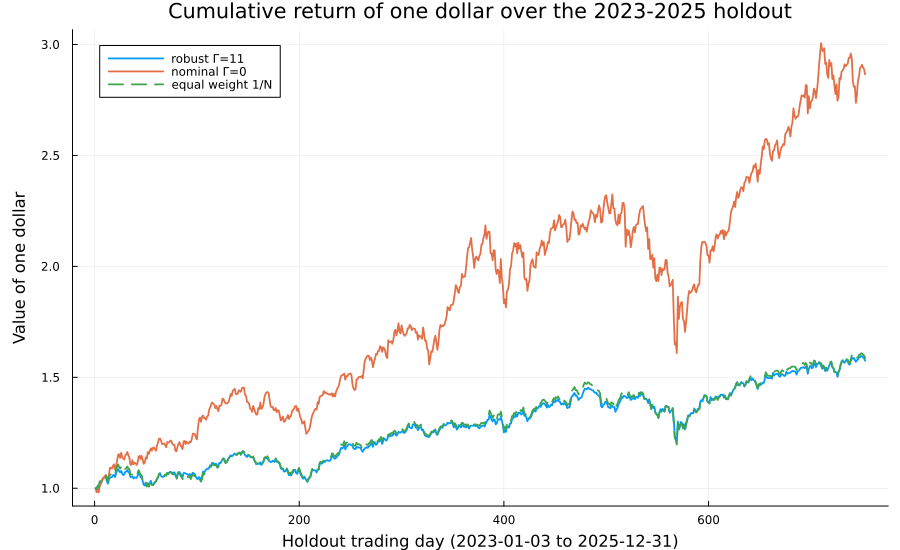

In [12]:
plt_oos = plot(hcat([vcat(1.0, cumprod(1 .+ Rho * x)) for (_, x) in books]...),
               label = permutedims(first.(books)), linestyle = [:solid :solid :dash],
               linewidth = 1.8, legend = :topleft, size = (900, 550), left_margin = 5Plots.mm,
               xlabel = "Holdout trading day (2023-01-03 to 2025-12-31)",
               ylabel = "Value of one dollar",
               title = "Cumulative return of one dollar over the 2023-2025 holdout")
savefig(plt_oos, "fig_holdout.png")
plt_oos


One holdout window is one draw. The nominal book won on 2023-2025 because the industry it bet everything on happened to finish 2nd of 30, which nothing in the model could have known in advance, so that single result cannot separate skill from luck. The next cell repeats the entire protocol across the century of data the library provides: fit six years, pick $\Gamma^*$ on the next two, refit on all eight, score the following three, then step forward three years and start again. Test windows never overlap, and every round is reported.

We wrote down what we expected before running it. Protection only helps when the estimates fail, so we expected two things: a drawdown advantage that widens when the market itself falls hard, and a return cost across the calm periods where the protection is wasted.

Rounds where the validation step chooses $\Gamma^* = 0$ are separated out, because there the model declines to buy any protection and the two books are the same portfolio. Test windows are split by the drawdown of an equal-weight book, which knows nothing about our model.


31 test windows, 1934-2026. Γ* = 0 in 9 of them, so the model bought protection in 22

robust minus nominal, so a negative drawdown gap and a positive return gap favour robust


                     robust better     median   middle half
  maximum drawdown         19 of 22     -12.9 pp  -24.4 to  -5.4
  annual return            11 of 22       1.7 pp   -3.8 to  15.4

drawdown gap by market condition: -17.9 pp over the 12 stressed rounds, -8.7 pp over the 10 calm ones


against equal weight instead: smaller drawdown in 7 of 22 rounds, median gap 1.0 pp


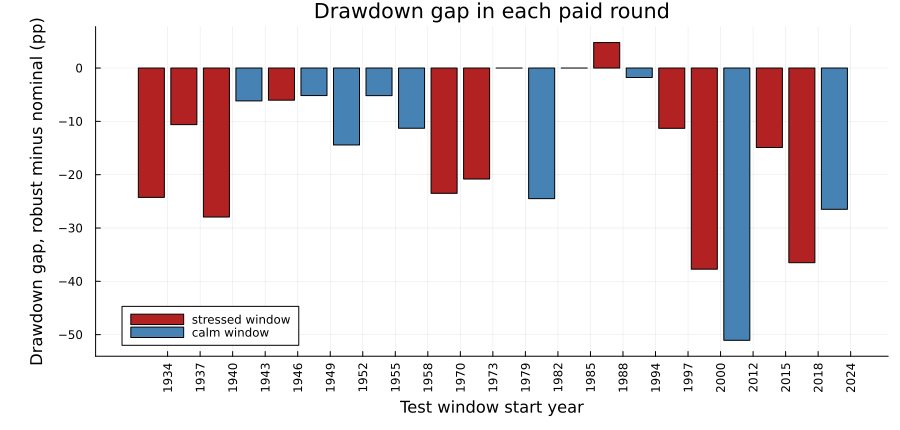

In [13]:
# the same protocol as above, repeated across a century instead of once. each round fits
# on 6 years, picks Γ* on the next 2, refits on all 8, and scores the following 3. rounds
# start every 3 years from 1926, so no two test windows overlap.
function one_round(y0)
    tr = win(dates, y0 * 10000 + 101, (y0 + 5) * 10000 + 1231)          # 6 years to fit
    va = win(dates, (y0 + 6) * 10000 + 101, (y0 + 7) * 10000 + 1231)    # 2 years to pick Γ*
    te = win(dates, (y0 + 8) * 10000 + 101, (y0 + 10) * 10000 + 1231)   # 3 years to score
    (sum(tr) < 1000 || sum(va) < 300 || sum(te) < 500) && return nothing # incomplete at the edges

    mu_f, d_f = fit_inputs(R[tr, :])
    X = [clean(solve_robust(mu_f, d_f, G)[1]) for G in 0:30]
    s = [sharpe(R[va, :] * x) for x in X]
    G = minimum([g for g in 0:30 if abs(s[g+1] - maximum(s)) < tie_tol])

    mu_e, d_e = fit_inputs(R[tr .| va, :])                              # refit on all 8 years
    rob, nom = clean(solve_robust(mu_e, d_e, G)[1]), clean(solve_robust(mu_e, d_e, 0)[1])
    ew = fill(1 / 30, 30)
    Rte = R[te, :]
    return (y0 = y0 + 8, G = G,
            ret_rob = ann_ret(Rte * rob), ret_nom = ann_ret(Rte * nom),
            ret_ew = ann_ret(Rte * ew),
            dd_rob = max_drawdown(Rte * rob), dd_nom = max_drawdown(Rte * nom),
            dd_ew = max_drawdown(Rte * ew))
end

rounds = filter(!isnothing, [one_round(y) for y in 1926:3:2016])

# where the validation step chose Γ* = 0 the model declined to buy any protection, the two
# books are the same portfolio, and there is nothing to compare. the rest are the rounds
# where robustness was actually paid for.
paid = [r for r in rounds if r.G > 0]
@printf("%d test windows, %d-%d. Γ* = 0 in %d of them, so the model bought protection in %d\n",
        length(rounds), rounds[1].y0, rounds[end].y0 + 2,
        length(rounds) - length(paid), length(paid))

# the nominal book is the controlled comparison: same LP, same inputs, only Γ differs, so
# any gap is attributable to robustness alone. quartiles are shown because the spread
# across rounds is wide and a median alone would hide it.
gap_dd = [r.dd_rob - r.dd_nom for r in paid]
gap_ret = [r.ret_rob - r.ret_nom for r in paid]
println("\nrobust minus nominal, so a negative drawdown gap and a positive return gap favour robust")
println("                     robust better     median   middle half")
@printf("  maximum drawdown %10d of %-3d %8.1f pp %6.1f to %5.1f\n", count(<(0), gap_dd),
        length(paid), median(gap_dd), quantile(gap_dd, .25), quantile(gap_dd, .75))
@printf("  annual return    %10d of %-3d %8.1f pp %6.1f to %5.1f\n", count(>(0), gap_ret),
        length(paid), median(gap_ret), quantile(gap_ret, .25), quantile(gap_ret, .75))

# a test window counts as stressed if an equal-weight book, which knows nothing about our
# model, drew down more than 20% in it. the rule uses the market, not our own results.
st = [r for r in paid if r.dd_ew > 20]
ca = [r for r in paid if r.dd_ew <= 20]
@printf("\ndrawdown gap by market condition: %.1f pp over the %d stressed rounds, %.1f pp over the %d calm ones\n",
        median([r.dd_rob - r.dd_nom for r in st]), length(st),
        median([r.dd_rob - r.dd_nom for r in ca]), length(ca))

# the same rounds scored against equal weight instead, which bounds what the LP can claim:
# beating a single-industry book only shows that diversifying helps.
gap_ew = [r.dd_rob - r.dd_ew for r in paid]
@printf("against equal weight instead: smaller drawdown in %d of %d rounds, median gap %.1f pp\n",
        count(<(0), gap_ew), length(paid), median(gap_ew))

# the 22 gaps as one picture. bars below zero are rounds the robust book lost less, and
# the coloring reuses the stress rule above.
xs = string.(getfield.(paid, :y0))
g_st = [paid[i].dd_ew > 20 ? gap_dd[i] : NaN for i in eachindex(paid)]
g_ca = [paid[i].dd_ew > 20 ? NaN : gap_dd[i] for i in eachindex(paid)]
p_roll = bar(xs, g_st, label = "stressed window", color = :firebrick,
             xrotation = 90, size = (900, 430), bottom_margin = 8Plots.mm,
             left_margin = 10Plots.mm, xticks = (1:length(xs), xs),
             ylims = (minimum(gap_dd) - 3, maximum(gap_dd) + 3),
             xlabel = "Test window start year",
             ylabel = "Drawdown gap, robust minus nominal (pp)",
             title = "Drawdown gap in each paid round")
bar!(p_roll, xs, g_ca, label = "calm window", color = :steelblue)
savefig(p_roll, "fig_rolling_gap.png")
p_roll


One number in all of the above was ours rather than the model's: the multiplier 2 in $d_i = 2\,\mathrm{SE}_i$. Nothing in the optimization requires it, so the last cell rebuilds the uncertainty vector as $d_i = k\,\mathrm{SE}_i$ for $k = 1, 2, 3$ and reruns the whole $\Gamma$ sweep once per value. A larger $k$ is a deeper attack on each industry the adversary touches, while $\Gamma$ still sets how many it may touch.

k = 1: peak 17 industries, collapses at Γ =  7 to BusEq  plateau    9.92%
k = 2: peak 30 industries, collapses at Γ = 17 to BusEq  plateau    1.28%


k = 3: peak 30 industries, collapses at Γ = 22 to BusEq  plateau   -7.35%


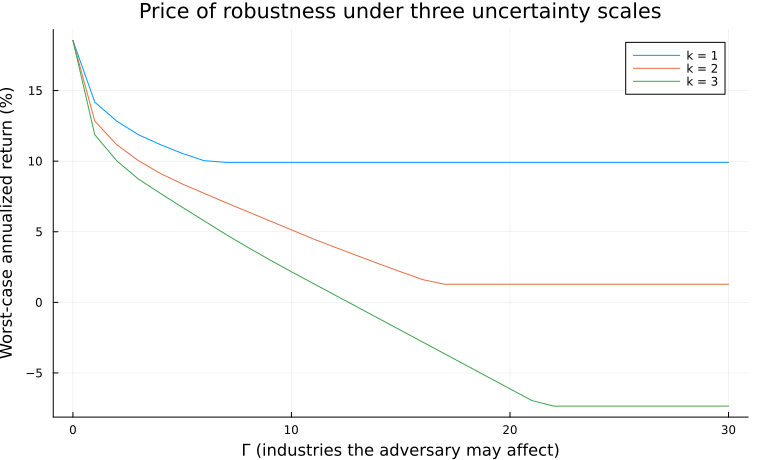

In [14]:
se = vec(std(Rest, dims=1)) ./ sqrt(T)   # SE_i of industry i's mean; the d above is 2 se

p_k = plot(xlabel = "Γ (industries the adversary may affect)", legend = :topright,
           ylabel = "Worst-case annualized return (%)", size = (760, 460),
           title = "Price of robustness under three uncertainty scales")
for k in (1, 2, 3)
    arm = [solve_robust(μ, k .* se, Γ) for Γ in Γ_range]   # the same sweep, one d per k
    Wk = [ann(a[2]) for a in arm]
    Hk = [count(a[1] .> 1e-4) for a in arm]                # holdings, above solver dust
    # the collapse budget is the start of the terminal run of single-industry books, not
    # the first budget holding one, which would be Γ = 0 on every arm.
    @printf("k = %d: peak %2d industries, collapses at Γ = %2d to %-6s plateau %7.2f%%\n",
            k, maximum(Hk), Γ_range[findlast(Hk .> 1) + 1],
            industries[argmax(arm[end][1])], Wk[end])
    plot!(p_k, Γ_range, Wk, label = "k = $k")
end
savefig(p_k, "fig_k_curves.png")
p_k


## 4. Results discussion ##

### 4.A. Estimation uncertainty in the inputs

Annualized mean returns across the 30 industries span 2.2% to 18.5%, while the uncertainty scales $d_i$ span 11.2% to 38.8%: the error bars are wider than the entire spread of the means. On their own, the estimated means are too unreliable to steer an optimizer. This is the premise of the project.

![Annualized mean of each industry with its ±d band, estimated on 2015-2022.](fig_inputs.png)

*Annualized mean of each industry with its ±d band, estimated on 2015-2022.*

### 4.B. Toy-problem validation

For every $\Gamma$ from 0 to 5, the dual-reformulation LP, the subset-enumeration LP, and the direct sort computation agree to solver precision, with a largest difference of $1.63 \times 10^{-19}$, so the dualization that carries the whole project is implemented correctly.

### 4.C. Portfolio composition along the robustness path

The path is not monotone. At $\Gamma = 0$ the optimizer puts all capital into Business Equipment, the industry with the highest estimated mean. By $\Gamma = 5$ the portfolio holds 25 industries, and four of its five largest weights go to Food, Household, Beer and Health, a classically defensive group. By $\Gamma = 15$ it holds all 30, and from $\Gamma = 17$ onward it collapses back to a single holding. Both endpoints follow from the model structure (the $\Gamma = 0$ solution is the argmax of $\hat\mu_i$, the $\Gamma = 30$ solution is the argmax of $\hat\mu_i - d_i$); the empirical content is the interior diversification and the location of the collapse. One result differs from what our proposal anticipated: we expected the extreme-$\Gamma$ survivor to be a defensive industry, but the penalty-adjusted winner is Business Equipment again, because its estimated mean is large enough to survive its own volatility penalty. The defensive tilt appears at moderate $\Gamma$ instead.

![Number of industries held as the adversary's budget grows.](fig_holdings.png)

*Number of industries held as the adversary's budget grows.*

### 4.D. The price of robustness

The price is front-loaded. The first five units of protection cost 10.2 percentage points of worst-case annualized return (18.55% down to 8.39%), the next ten cost 6.2 points (8.39% down to 2.17%), and past the collapse near $\Gamma = 17$ protection is free: the portfolio depends on one estimate again and the worst case has settled at 1.28%, where it stays out to $\Gamma = 30$. The $\Gamma = 0$ endpoint of that curve is degenerate: with no adversary the objective is just an estimated mean, not a worst case. The slope check confirms the duality prediction: on linear stretches of the curve ($\Gamma = 5$ and $\Gamma = 7$ through $9$) the finite difference equals $-z^*$ exactly. The small-$\Gamma$ rows differ because a breakpoint of the piecewise-linear curve falls inside the unit step, and at $\Gamma = 0$ the budget constraint is vacuous, so $z^*$ is not unique.

![Guaranteed worst-case return against the adversary's budget.](fig_price_curve.png)

*Guaranteed worst-case return against the adversary's budget.*


### 4.E. Out-of-sample results

Everything above is in-sample. This subsection scores the frozen books on 2023-2025, which no fitting step saw. The comparison is against the nominal book, the same LP with the same inputs and $\Gamma = 0$, so robustness is the only difference between the two; equal weight is carried as a reference.

The validation Sharpe is not monotone in $\Gamma$. It falls from $-0.2279$ at $\Gamma = 0$ to $-0.2741$ at $\Gamma = 1$, peaks at $0.2204$ at $\Gamma = 11$, and is back to $0.1618$ by $\Gamma = 13$, where the train fit holds a single industry again. The rule picks $\Gamma^* = 11$, with 26 industries.

The table is judged on the same Sharpe that chose $\Gamma^*$; return and volatility are its two components. Drawdown is included because the prediction written down for the rolling test of 4.F is about drawdown.

| portfolio | ann. return | ann. vol | Sharpe | max drawdown |
|---|---|---|---|---|
| robust $\Gamma^* = 11$ | 16.16% | 13.71% | 1.1789 | 17.05% |
| equal weight $1/N$ | 16.56% | 14.74% | 1.1235 | 18.98% |
| nominal $\Gamma = 0$ | 38.70% | 26.17% | 1.4791 | 30.76% |

We lost. The nominal book returned 38.70% a year against our 16.16% and its Sharpe of 1.4791 beats our 1.1789, so the prediction that protection would pay off out of sample is refuted on this window. The certified worst-case floor of 4.49% did hold; the realized 16.16% clears it easily. The robust book also beats equal weight here, 1.1789 against 1.1235 with both risk columns better, at a cost of 0.40 points of return.

The reason the nominal book won is in the diagnostics. Only 1 of the 30 industries realized a mean below $\hat\mu_i - d_i$, and BusEq, the nominal book's single holding, finished 2nd of 30 on holdout mean. The event the uncertainty set insures against did not happen, and the concentrated bet was nearly the best one available. A window in which the estimates hold up is a window in which protection is wasted.

![Growth of one dollar in each book over the 2023-2025 holdout.](fig_holdout.png)

*Growth of one dollar in each book over the 2023-2025 holdout.*

In the chart the robust and equal-weight paths are nearly indistinguishable.

The robust book's clearest win is risk: volatility of 13.71% against 26.17%, and the smallest drawdown of the three, 17.05% against 30.76%. The model has no risk term, so this is diversification doing the work, not the LP optimizing risk.

Deleting every row dated after 2022 and rerunning the whole selection reproduces $\Gamma^* = 11$ with a largest weight difference of 0, so nothing from the holdout reached the frozen books. The loss is real.


### 4.F. Was that one window representative?

One three-year window cannot separate a broken model from an unlucky test period, so we reran the identical protocol across the century: fit on six years, pick $\Gamma^*$ on the next two, refit on all eight, score the following three, and step forward three years, starting in 1926. That gives 31 rounds with non-overlapping test periods from 1934 to 2026; the fit windows do overlap.

In 9 of the 31 rounds the validation step chose $\Gamma^* = 0$ and bought no protection, which leaves 22 rounds where robustness was paid for. In those 22 the robust book had the smaller maximum drawdown 19 times, with a median gap of $-12.9$ percentage points and a middle half from $-24.4$ to $-5.4$.

We had written down beforehand that the gap should widen when markets fall. It does: a median of $-17.9$ points across the 12 windows where an equal-weight book lost more than 20%, against $-8.7$ across the 10 calmer ones.

![Maximum-drawdown gap, robust minus nominal, in the 22 rounds that bought protection; a bar below zero is a round the robust book lost less.](fig_rolling_gap.png)

*Maximum-drawdown gap, robust minus nominal, in the 22 rounds that bought protection; a bar below zero is a round the robust book lost less.*

The second prediction, a return cost on average, did not hold. The robust book had the higher annual return in 11 of 22 rounds, with a median gap of $1.7$ points in its favour and a middle half from $-3.8$ to $15.4$. A spread that wide makes it a coin flip rather than an edge, but it is enough to say the systematic cost we expected is not there. Against this distribution, 4.E is a draw from the left tail, not the model failing.

So against the nominal book the model does its job: smaller worst losses, most clearly in bad markets, at no systematic cost in return.

Beating the nominal book is a low bar, though. It holds one industry, so the comparison mostly measures diversification. Scored against equal weight, the robust book has the smaller drawdown in only 7 of the 22 rounds, with a median gap of $1.0$ point in the wrong direction: the advantage disappears against a book that already diversifies. This matches DeMiguel, Garlappi and Uppal (2009), that naive diversification is hard to beat when the inputs are estimated. The model is a principled route to diversification, not an improvement on it.

If what the model adds is diversification, the $2$ in $d_i = 2\,\mathrm{SE}_i$ is the one choice left to check, and 4.G does.


### 4.G. Sensitivity to the multiplier in $d_i = k\,\mathrm{SE}_i$

The shape of the report's results does not depend on the multiplier. All three curves are decreasing and convex, every one of them runs from a single industry out to many and back to a single industry, and the industry left standing after the collapse is BusEq at $k = 1$, $2$ and $3$ alike.

![The same sweep rerun with d = k x SE for k = 1, 2, 3.](fig_k_curves.png)

*The same sweep rerun with d = k x SE for k = 1, 2, 3.*

The numbers attached to that shape do depend on it, so they should be read as choice-dependent rather than as properties of the model. The collapse budget moves later as $k$ grows, from $\Gamma = 7$ to 17 to 22, because a deeper per-industry attack keeps diversification worth paying for over a wider range of attack breadths. The plateau the portfolio settles onto moves with it, from $9.92\%$ to $1.28\%$ to $-7.35\%$, and peak diversification rises from 17 industries to all 30. The $\Gamma^* = 11$ of 4.E and the collapse at $\Gamma = 17$ in 4.C are therefore statements about $d = 2\,\mathrm{SE}$, not about robust portfolios in general.


### 4.H. Limitations

The probabilistic guarantee behind the model assumes estimation errors that are independent across assets, while the measured average pairwise correlation in our estimation window is 0.63, so the guarantee attached to a given $\Gamma$ is more optimistic than the data supports. The uncertainty set also covers only sampling noise around a fixed mean; across a century, estimates more often fail because the mean itself moved.

The rolling evidence is broad but not independent: the fit windows overlap, everything comes from one data source and one universe of 30 industries, and the stressed/calm split rests on 12 rounds against 10, too few for stable medians. No transaction costs are charged anywhere, which favours a 26-position book over a one-position book, and every Sharpe ratio uses a risk-free rate of zero.

Finally, the model is single-period and long-only, with no risk term, so nothing in it responds to the covariance structure a mean-variance formulation would use.


## 5. Conclusion ##
This project shows that robust optimization can reduce a portfolio’s dependence on uncertain return estimates, although it does not guarantee a higher realized return. With $d_i = 2\,\mathrm{SE}_i$, the nominal model at $\Gamma=0$ invests everything in Business Equipment. Moderate values of $\Gamma$ produce a much more diversified portfolio: the model holds 25 industries at $\Gamma=5$ and all 30 at $\Gamma=15$. However, from $\Gamma=17$ onward, it returns to a single Business Equipment position. Therefore, increasing conservatism does not always lead to greater diversification.

The validation procedure selected $\Gamma^*=11$, producing a portfolio with 26 industries. During the 2023–2025 holdout period, this portfolio earned an annualized return of 16.16%, with 13.71% volatility and a 17.05% maximum drawdown. The nominal portfolio earned a much higher return of 38.70%, but its volatility and maximum drawdown were also much higher. Therefore, the robust portfolio did not win on return or Sharpe ratio in this period, but it provided better downside protection.

The longer rolling experiment gives a more complete result. In the 22 test windows where the model selected positive protection, the robust portfolio had a smaller maximum drawdown than the nominal portfolio in 19 windows, with a median improvement of 12.9 percentage points. The improvement was larger during stressed markets. However, its annual return was higher in only 11 of the 22 windows, and its drawdown advantage largely disappeared relative to an equally weighted portfolio. Overall, the model’s main benefit is that it turns uncertain estimates into diversification and reduces the risk of a concentrated portfolio, rather than consistently outperforming simple diversification.

As for the possible future direction, a stochastic programming model will be introduced. Instead of adding an adversary, this model uses historical return data to maximize the expected return. It also focuses on the tail risk to capture events with a low probability of occurrence but a massive impact on returns. This is the Conditional Value-at-Risk (CVaR). For this CVaR stochastic programming model, the objective is to maximize the expected return across all historical trading days. A decision variable $v$ representing the Value-at-Risk (VaR) will be introduced as a warning threshold. A variable $e = \text{loss} - v$ will be introduced to represent loss amount exceeding the warning threshold ($e \geq 0$). Then, we will set a target proportion $t$ to limit the average proportion of the principal lost during the worst $x\%$ of trading days. $e$ will be used to calculate the losses on these worst $x\%$ trading days.